# CSDA Vendor Specs database: QA, update loop and constellation comparison

Reads the **Vendor Specs** tab of the CSDA specs Google Sheet live and:

1. **Checks columns A–AS** automatically (shifted cells, dates, vocabularies, inconsistent pairs such as off-nadir vs nadir
   GSD or orbit period vs altitude) and lists errors suspected from outside knowledge that need a source.
2. **Shows what is missing** (filled / empty grid of A–AS by sensor).
3. **Compares constellations**: image footprint (swath), GSD and number of bands.
4. **Lists proposed edits** from a public-source check (CSDA vendor pages first), with sources.
5. **Writes an interactive dashboard** (`html/vendor_specs.html`): hover any constellation for its specs and open flags.
6. **Supports the update loop** with vendor documents on SharePoint: builds a NASA Chat prompt that extracts A–AS for one
   constellation with page citations, then diffs the answer against the sheet.

**Update plan** (each step uses a section below)

| Step | What | Where |
|---|---|---|
| 1. Define the fields | Settle what each A–AS field means. **Decided 2 Nov 2026: *Total Bands (MS)* counts the pan band.** Still open: revisit per satellite or per constellation; GSD native or product | data dictionary, e.g. on the *SME needs* tab |
| 2. Fix structural errors | Shifted cells, swapped dates, text in number fields, status vocabulary | section 2 table (`vendor_specs_qa.csv`) |
| 3. Verify against sources | Priority: vendors CSDA is evaluating, then government references. Public specs: CSDA vendor pages (science.nasa.gov), vendor datasheets, USGS / ESA. SharePoint documents: NASA Chat with the section 8 prompt. Fill **Reference** for every row (25 of 84 have one) | sections 3, 8 |
| 4. Fill the gaps | Section 4 grid shows empty fields; decide which columns to keep (X, Y, AI, AR, AS are empty for every sensor) | section 4 |
| 5. Re-run | QA count falls, plots refresh from the live sheet | this notebook |

**Data handling.** Vendor material on SharePoint may be CUI (e.g. the Airbus TEM). Keep it in NASA Chat; bring back only
values cleared for the database.

Library: `lib/vendor_specs.py`.

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import vendor_specs as vs
importlib.reload(vs)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 70)

## Parameters

In [2]:
SHEET_ID = vs.SHEET_ID                 # 'NASA CSDA ... Vendor Specs' Google Sheet (shared 'anyone with the link')
GID = vs.GID['Vendor Specs']

# Constellations to compare: 'current' = operational / constellation / limited (or no status yet); 'all' = every row
SCOPE = 'current'
SECTORS = ['Commercial', 'Government']

# Display names for constellation groups (group name built from the sheet -> name on the plots)
LABELS = {'NewSat Mark I': 'Satellogic Mark I', 'NewSat Mark II': 'Satellogic Mark II', 'NewSat Mark III': 'Satellogic Mark III',
          'NewSat Mark IV': 'Satellogic Mark IV', 'NewSat Mark V': 'Satellogic Mark V',
          'GEISAT GEISAT-P': 'Satlantis GEISAT-P', 'GEISAT HORACIO': 'Satlantis HORACIO',
          'OSK GHOSt-3/GHOSt-4/GHOSt-5': 'OSK GHOSt', 'OSK GHOSt-6': 'OSK GHOSt-6',
          'ImageSat EROS-C2/EROS-C3': 'ImageSat EROS-C2/C3', 'PleiadesNeo': 'Pléiades Neo', 'Pleiades': 'Pléiades',
          'HydroSat': 'Hydrosat VanZyl', 'Kuva': 'Kuva Hyperfield', 'FireSat': 'FireSat (proto)'}

# Proposed edits from the public-source check (CSV in the repo)
EDITS_CSV = '/home/pmontesa/code/csda_summaries/specs/public_check_2026-11-02.csv'
EDITS_DATE = '2 Nov 2026'

OUT_DIR = Path('vendor_specs_out')     # QA table and figures (PNG)
DASHBOARD = Path('../html/vendor_specs.html')   # interactive dashboard (GitHub Pages: html/vendor_specs.html)
DPI = 200
OUT_DIR.mkdir(exist_ok=True)

## 1. Load the sheet

Text as entered (no type conversion); `sheet_row` is the row number in the sheet, `label` = constellation + sensor.

In [3]:
raw = vs.load(vs.csv_url(SHEET_ID, GID))
core = vs.core_fields(raw)
print(f"{len(raw)} sensors, {len(raw.columns) - 2} columns; core fields A-AS: {len(core)} "
      f"({core[0]} ... {core[-1]})")
raw[['sheet_row', 'label', 'Affiliation', 'Sector', 'Mission Status', 'Launch Date']].head()

84 sensors, 102 columns; core fields A-AS: 45 (Sensor Name ... Radiometric Temporal Stability (%))


,sheet_row,label,Affiliation,Sector,Mission Status,Launch Date
0,2,PleiadesNeo PNEO3,Airbus,Commercial,Operational,2021-04-28
1,3,PleiadesNeo PNEO4,Airbus,Commercial,Operational,2021-08-16
2,4,Pleiades PHR1A,Airbus,Commercial,Operational,2011-12-17
3,5,Pleiades PHR1B,Airbus,Commercial,Operational,2012-12-02
4,6,SPOT SPOT6,Airbus,Commercial,Operational,2012-09-09


## 2. Automated checks (columns A–AS and band counts)

One row per suspect cell: `column` is the sheet column letter. The checks find structural problems; they cannot say a
value is right. Saved to `vendor_specs_qa.csv` for working through in the sheet.

| check | meaning |
|---|---|
| shifted cells? | text where Yes / No belongs (or a number): cells from there right are probably one or more columns off |
| off-nadir finer than nadir | off-nadir GSD minimum below the nadir GSD |
| period vs altitude | orbit period differs > 1.5 min from a circular orbit at that altitude |
| MS count leaves out pan | rule: *Total Bands (MS)* counts pan; the row has a pan range but the count equals the MS ranges only |
| band count vs band ranges | *Total Bands (MS)* differs from the filled band ranges (16 named slots; sensors with more bands skipped) |
| size class vs mass | class does not match the mass ranges (Nano < 10 kg ... Large > 1000 kg) |
| status vs launch / end date | e.g. Planned with a past launch date, Constellation with a past End Date |
| not in vocabulary, date format, not a number, missing | entry does not follow the field's format |

In [4]:
issues = vs.qa_checks(raw)
issues.to_csv(OUT_DIR / 'vendor_specs_qa.csv', index=False)
print(f"{len(issues)} suspect cells in {issues.sheet_row.nunique()} of {len(raw)} rows -> {OUT_DIR / 'vendor_specs_qa.csv'}")
issues.groupby('check').agg(cells=('sheet_row', 'size'), rows=('sheet_row', 'nunique'),
                            columns=('column', lambda c: ', '.join(sorted(set(c))))).sort_values('cells', ascending=False)

75 suspect cells in 45 of 84 rows -> vendor_specs_out/vendor_specs_qa.csv


,cells,rows,columns
check,,,
missing,14,13,"B, J, T, U"
off-nadir finer than nadir,13,7,"AD, AF"
MS count leaves out pan,12,12,CI
period vs altitude,8,8,O
band count vs band ranges,5,5,CI
shifted cells?,5,3,"AK, AL"
size class vs mass,5,5,K
not a number,4,4,AJ
not in vocabulary,2,2,J


In [5]:
issues

,sheet_row,label,column,field,value,check,detail
0,8,Global Gen 1,CI,Total Bands (MS),3,MS count leaves out pan,3 MS band ranges + pan = 4; Total Bands (MS) = 3 (rule: count pan)
1,9,Global Gen 2,CI,Total Bands (MS),3,MS count leaves out pan,3 MS band ranges + pan = 4; Total Bands (MS) = 3 (rule: count pan)
2,10,Global Gen 3,CI,Total Bands (MS),4,MS count leaves out pan,4 MS band ranges + pan = 5; Total Bands (MS) = 4 (rule: count pan)
3,11,Aurora EDA,O,Orbit Period (min),95,period vs altitude,600 km gives 96.7 min (circular orbit)
4,12,Envisat MERIS,CI,Total Bands (MS),15,band count vs band ranges,"8 MS band ranges filled = 8, Total Bands (MS) = 15"
5,13,Sentinel 2A (MSI),CI,Total Bands (MS),13,band count vs band ranges,"11 MS band ranges filled = 11, Total Bands (MS) = 13"
6,14,Sentinel 2B (MSI),CI,Total Bands (MS),13,band count vs band ranges,"11 MS band ranges filled = 11, Total Bands (MS) = 13"
7,15,Sentinel 2C (MSI),CI,Total Bands (MS),13,band count vs band ranges,"11 MS band ranges filled = 11, Total Bands (MS) = 13"
8,16,Sentinel 2D (MSI),CI,Total Bands (MS),13,band count vs band ranges,"11 MS band ranges filled = 11, Total Bands (MS) = 13"
9,20,Sentinel 3D (OLCI/SLSTR),J,Mission Status,Planned,status vs launch,Planned but the launch date has passed


## 3. Public-source check: proposed edits

From the public-source check of 2 Nov 2026 (`specs/public_check_2026-11-02.csv`): one row per proposed cell
change, with the current sheet value, the proposed value and its source. Sources, in order of preference: the **CSDA vendor
pages** on science.nasa.gov, vendor / agency pages, then secondary sites; *computed* = derived from other fields (e.g. orbit
period from altitude). None of it is applied to the sheet yet: review, edit the sheet, re-run.

Not covered yet: launch dates, masses and altitudes for most vendors (the CSDA pages rarely give them), EarthDaily,
government sensors other than Landsat 7, and most columns from AM (bit depth) on.

In [6]:
edits = vs.load_edits(EDITS_CSV)
print(f"{len(edits)} proposed edits; by source:", edits.source.value_counts().to_dict())
edits

87 proposed edits; by source: {'CSDA vendor page': 71, 'computed': 5, 'vendor page': 4, 'agency page': 4, 'secondary': 2, 'definition (MS counts pan)': 1}


,sheet_rows,sensors,column,field,current,proposed,source,source_url,note,change
0,2-3,"PleiadesNeo PNEO3, PleiadesNeo PNEO4",CI,Total Bands (MS),6,7,CSDA vendor page,https://science.nasa.gov/earth-science/csda/vendor-airbus/,"6 MS (deep blue, blue, green, red, red edge, NIR) + pan",True
1,2-3,"PleiadesNeo PNEO3, PleiadesNeo PNEO4",CJ,Total Bands,6,7,CSDA vendor page,https://science.nasa.gov/earth-science/csda/vendor-airbus/,,True
2,2-3,"PleiadesNeo PNEO3, PleiadesNeo PNEO4",AV,Coastal Min (nm),(empty),400,CSDA vendor page,https://science.nasa.gov/earth-science/csda/vendor-airbus/,deep blue 400-450 nm missing from the band ranges,True
3,2-3,"PleiadesNeo PNEO3, PleiadesNeo PNEO4",AW,Coastal Max (nm),(empty),450,CSDA vendor page,https://science.nasa.gov/earth-science/csda/vendor-airbus/,,True
4,2-3,"PleiadesNeo PNEO3, PleiadesNeo PNEO4",L,Weight Range (kg),350,~900-920,secondary,https://eoportal.org/satellite-missions/pleiades-neo,sources give 900 (S950 bus) to 920 kg; not on the CSDA page,True
5,2-3,"PleiadesNeo PNEO3, PleiadesNeo PNEO4",K,Satellite Size Class,Mini,Medium,computed,,follows from ~900 kg,True
6,2-3,"PleiadesNeo PNEO3, PleiadesNeo PNEO4",AH,"Geolocation Accuracy (CE90, m)",3.5,<5 (3.5 expected),agency page,https://earth.esa.int/eogateway/missions/pleiades-neo,spec <5 m CE90; 3.5 m with refined orbit data,True
7,31-36,"Legion LG-1, Legion LG-2, Legion LG-3, Legion LG-4, Legion LG-5, L...",CI,Total Bands (MS),8,9,CSDA vendor page,https://science.nasa.gov/earth-science/csda/vendor-vantor/,pan + 8 MS,True
8,31-36,"Legion LG-1, Legion LG-2, Legion LG-3, Legion LG-4, Legion LG-5, L...",O,Orbit Period (min),~97,~95,computed,,518 km circular orbit = 95.0 min,True
9,31-36,"Legion LG-1, Legion LG-2, Legion LG-3, Legion LG-4, Legion LG-5, L...",AD,Pan GSD Off-Nadir Min (m),0.32,>= 0.34,computed,,off-nadir GSD cannot be finer than nadir 0.34 m,True


## 4. What is filled in

Dark = the field has a value. The numbers on top are the share of sensors with the field filled.

Least filled sensors: GHOSt-6 (22%), GHOSt-5 (31%), ImageSat EROS-C2 (33%), ImageSat EROS-B (33%), ImageSat Runner-1 (33%), ImageSat EROS-C3 (33%), GHOSt-4 (33%), GHOSt-3 (33%), HydroSat VanZyl-2 (36%), ImageSat EROS-A (36%)


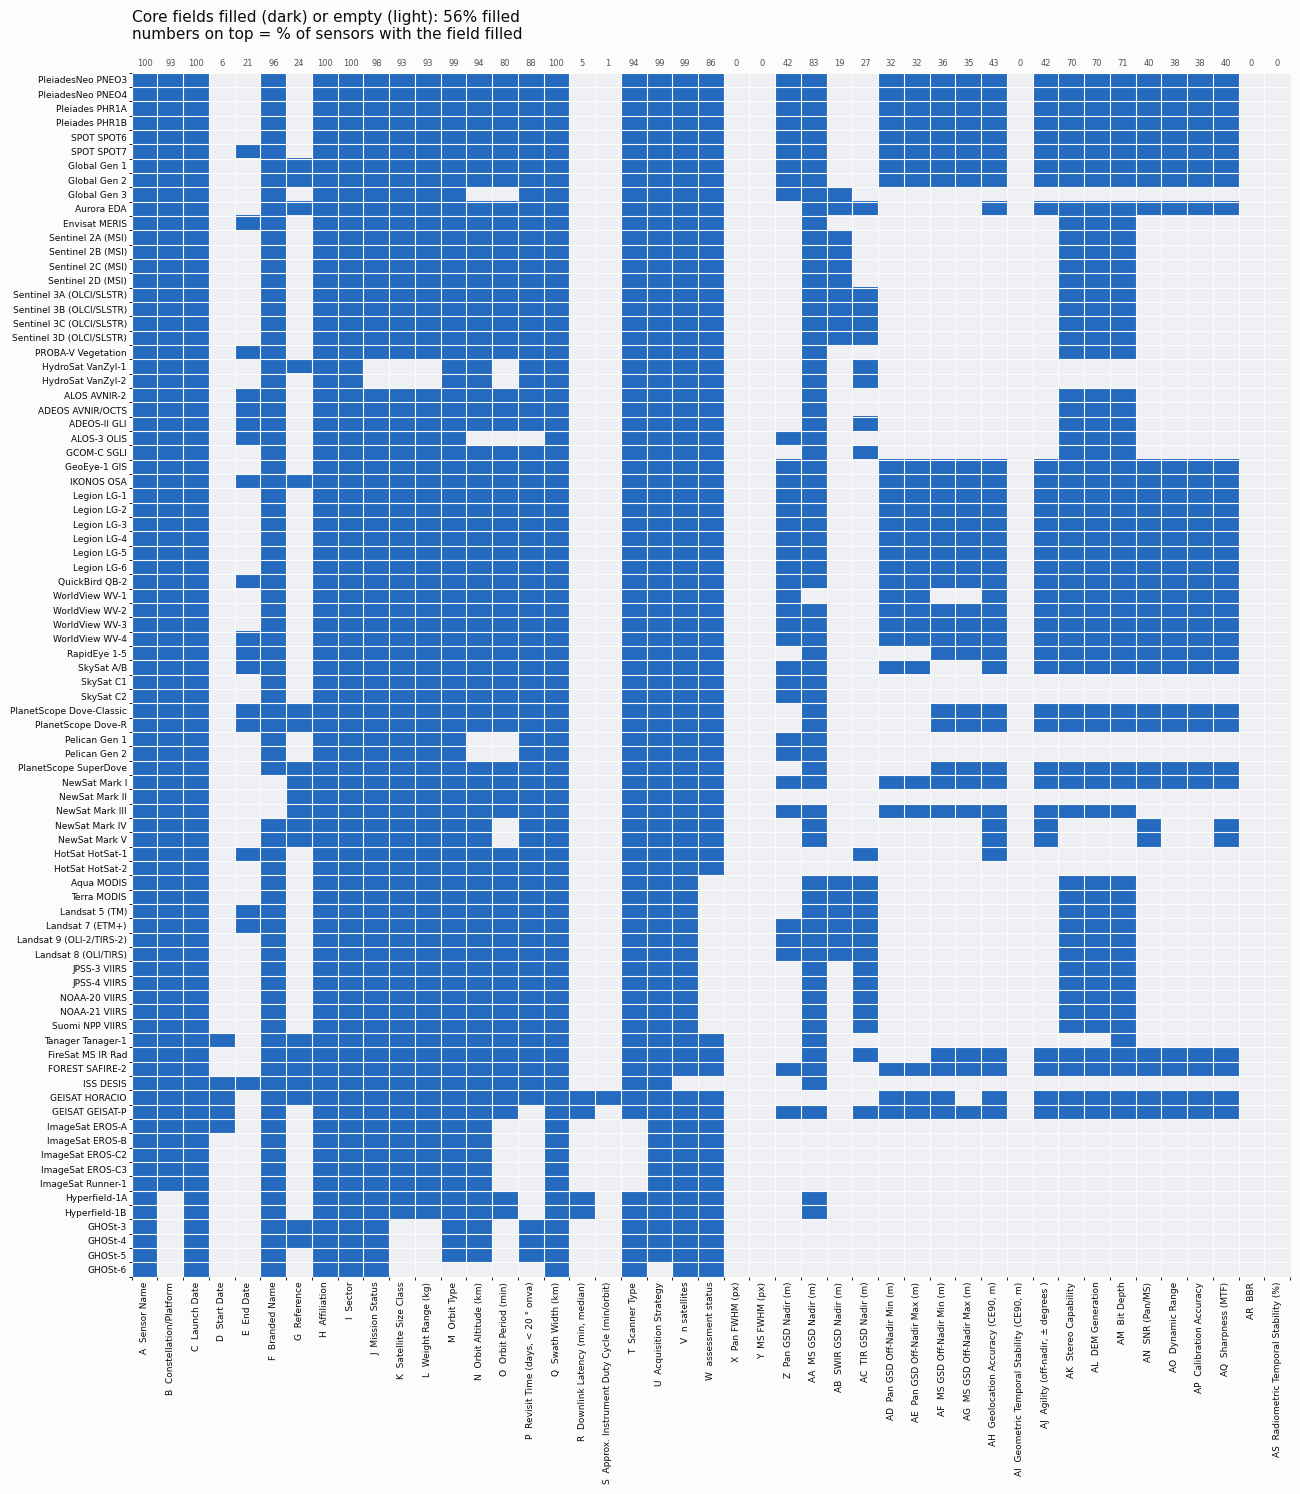

In [7]:
fig = vs.plot_completeness(raw)
fig.savefig(OUT_DIR / 'vendor_specs_completeness.png', dpi=DPI, bbox_inches='tight', facecolor=fig.get_facecolor())
filled = vs.completeness(raw)
print('Least filled sensors:', ', '.join(f"{k} ({v:.0%})" for k, v in filled.mean(axis=1).sort_values().head(10).items()))

## 5. Constellations compared: footprint, GSD, number of bands

Sensors of one data owner with the same GSD, swath and band count are merged into one group (e.g. Legion LG-1 to LG-6,
VIIRS on four platforms). Numbers are parsed from the text (`~97` -> 97, ranges -> first value). Band counts of rows with
shifted cells are not used. **\*** on a plot = one of the plotted values (GSD, swath, band count) is flagged in section 2
or has a proposed edit in section 3: check it before quoting it. A **black ring** marks a constellation with a pan band.

In [8]:
shifted = sorted(issues.loc[issues.check == 'shifted cells?', 'sheet_row'].unique())
all_groups = vs.constellations(raw, labels=LABELS, drop_rows=shifted)
groups = all_groups
if SCOPE == 'current':
    groups = groups[groups.current]
groups = groups[groups.sector.isin(SECTORS)].reset_index(drop=True)

# Groups with a flagged plotted value: section 2 issues or section 3 proposed edits on the plotted fields
plotted = ['Pan GSD Nadir (m)', 'MS GSD Nadir (m)', 'Swath Width (km)', 'Total Bands (MS)']
flag_rows = set(issues.loc[issues.field.isin(plotted), 'sheet_row'])
flag_rows |= {r for spec in edits.loc[edits.field.isin(plotted) & (edits.change == 'True'), 'sheet_rows'] for r in vs._rows(spec)}
FLAGGED = [g for g, rows in zip(groups.group, groups.sheet_rows)
           if flag_rows & {int(r) for r in rows.split(', ')}]
print(f"{len(groups)} constellation groups ({SCOPE}); flagged: {', '.join(FLAGGED)}")
groups[['group', 'affiliation', 'sector', 'sensors', 'status', 'pan_gsd', 'ms_gsd', 'swath_km', 'ms_bands',
        'total_bands', 'revisit_days', 'ce90_m', 'scanner']]

42 constellation groups (current); flagged: Pelican Gen 2, Pelican Gen 1, Satellogic Mark IV, Satellogic Mark V, SkySat C2, SkySat C1, Pléiades Neo, BlackSky Gen 3, WorldView-3, Legion, WorldView-2, PlanetScope Dove-R, PlanetScope SuperDove, OroraTech, BlackSky Gen 1, BlackSky Gen 2, FireSat (proto), Satlantis GEISAT-P, Kuva Hyperfield, Hydrosat VanZyl, ImageSat EROS-B, ImageSat EROS-C2/C3, OSK GHOSt, Sentinel-2


,group,affiliation,sector,sensors,status,pan_gsd,ms_gsd,swath_km,ms_bands,total_bands,revisit_days,ce90_m,scanner
0,Pelican Gen 2,Planet Labs,Commercial,Gen 2,Constellation,0.30,0.30,6.0,NaN,NaN,0.5,NaN,Pushbroom
1,Pelican Gen 1,Planet Labs,Commercial,Gen 1,Constellation,0.30,0.50,8.0,NaN,NaN,0.5,NaN,Pushbroom
2,Satellogic Mark IV,Satellogic,Commercial,Mark IV,Constellation,NaN,0.70,5.0,4.0,5.0,1.0,30.0,Pushframe
3,Satellogic Mark V,Satellogic,Commercial,Mark V,Constellation,NaN,0.73,6.5,4.0,5.0,1.0,30.0,Pushframe
4,SkySat C2,Planet Labs,Commercial,C2,Constellation,0.72,0.75,5.5,NaN,NaN,1.0,NaN,Pushframe
5,SkySat C1,Planet Labs,Commercial,C1,Constellation,0.72,0.80,5.9,NaN,NaN,1.0,NaN,Pushframe
6,SkySat A/B,Planet Labs,Commercial,A/B,Constellation,0.86,1.00,8.0,5.0,5.0,1.0,5.0,Frame/Video
7,Satellogic Mark I,Satellogic,Commercial,Mark I,Constellation,1.00,1.00,5.0,4.0,4.0,0.5,10.0,Pushbroom
8,Satellogic Mark III,Satellogic,Commercial,Mark III,Constellation,1.00,1.00,5.0,NaN,NaN,0.5,30.0,Pushbroom
9,Pléiades Neo,Airbus,Commercial,"PNEO3, PNEO4",Operational,0.30,1.20,14.0,6.0,6.0,1.0,3.5,Pushbroom


### Footprint vs. detail

Each constellation by its multispectral GSD (x) and swath width (y), both log scales; marker size = number of bands,
color = sector. The dashed diagonals count **pixels across the swath** (swath / GSD): most sensors, from 30 cm VHR to
VIIRS, sit between about 3,000 and 30,000 pixels across, so a finer GSD buys a proportionally narrower footprint.

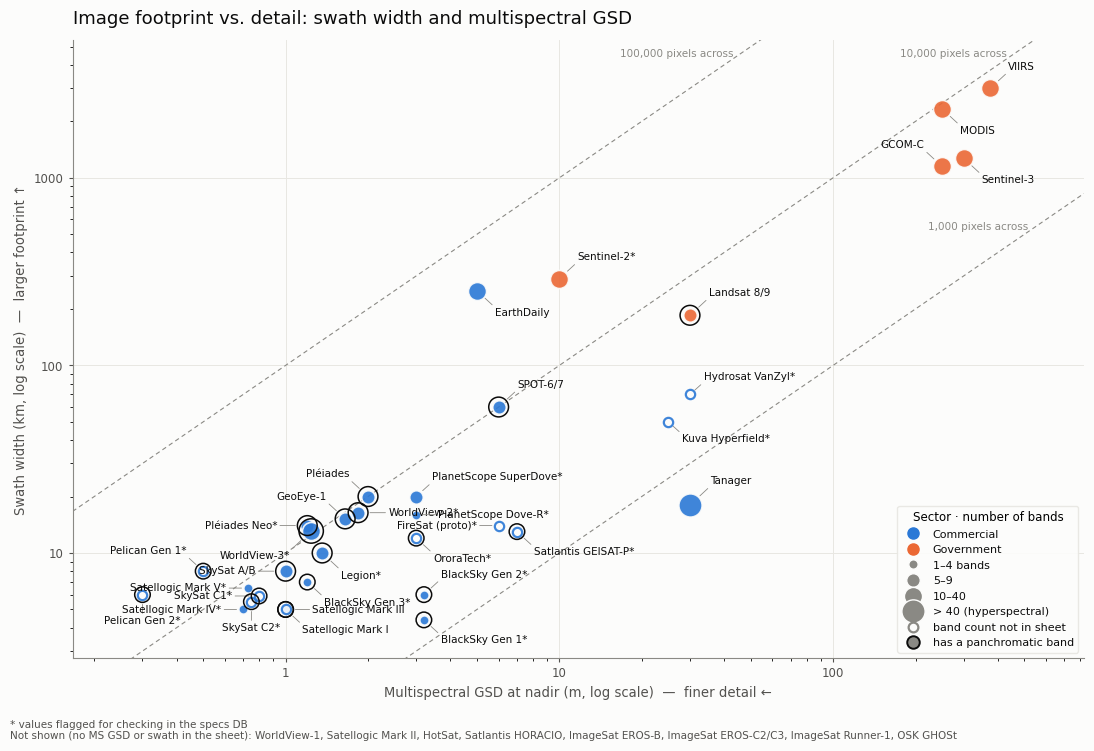

In [9]:
fig = vs.plot_gsd_swath(groups, flagged=FLAGGED)
fig.savefig(OUT_DIR / 'specs_gsd_vs_swath.png', dpi=DPI, bbox_inches='tight', facecolor=fig.get_facecolor())

### Key specs side by side

One row per constellation, sorted by multispectral GSD; three aligned panels with their own (log) axes: GSD (filled =
multispectral, open = panchromatic), swath width, number of bands.

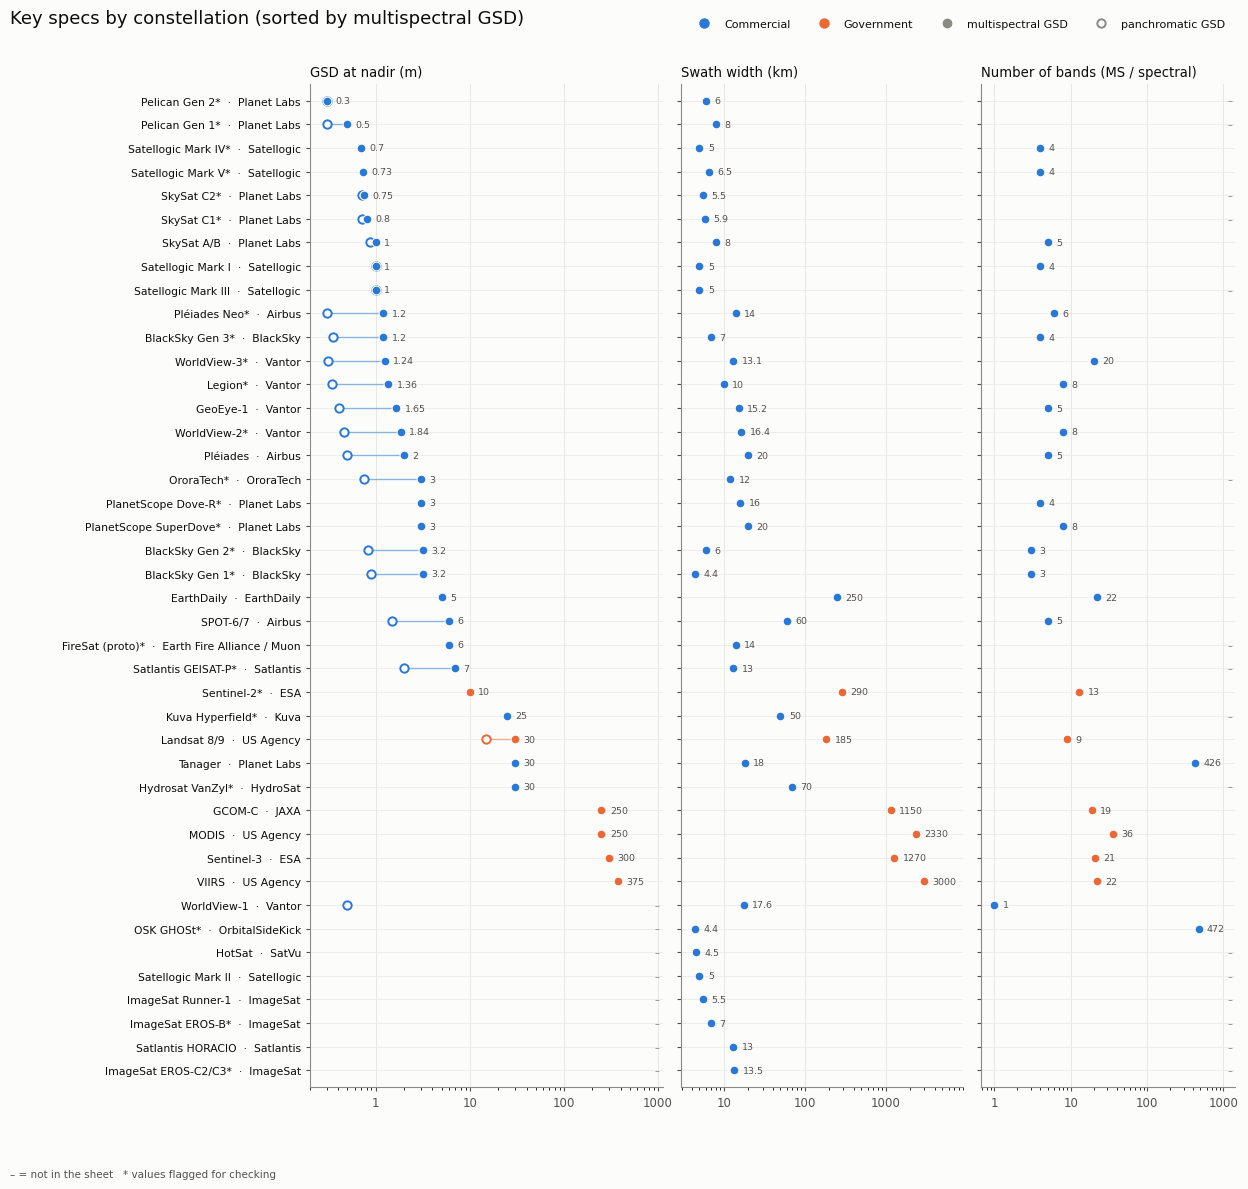

In [10]:
fig = vs.plot_spec_strips(groups, flagged=FLAGGED)
fig.savefig(OUT_DIR / 'specs_strips.png', dpi=DPI, bbox_inches='tight', facecolor=fig.get_facecolor())

### Image footprints at true scale

Every panel has the same km extent, so square sizes compare directly. The wide-swath government sensors are listed
under the figure instead (they would fill many panels).

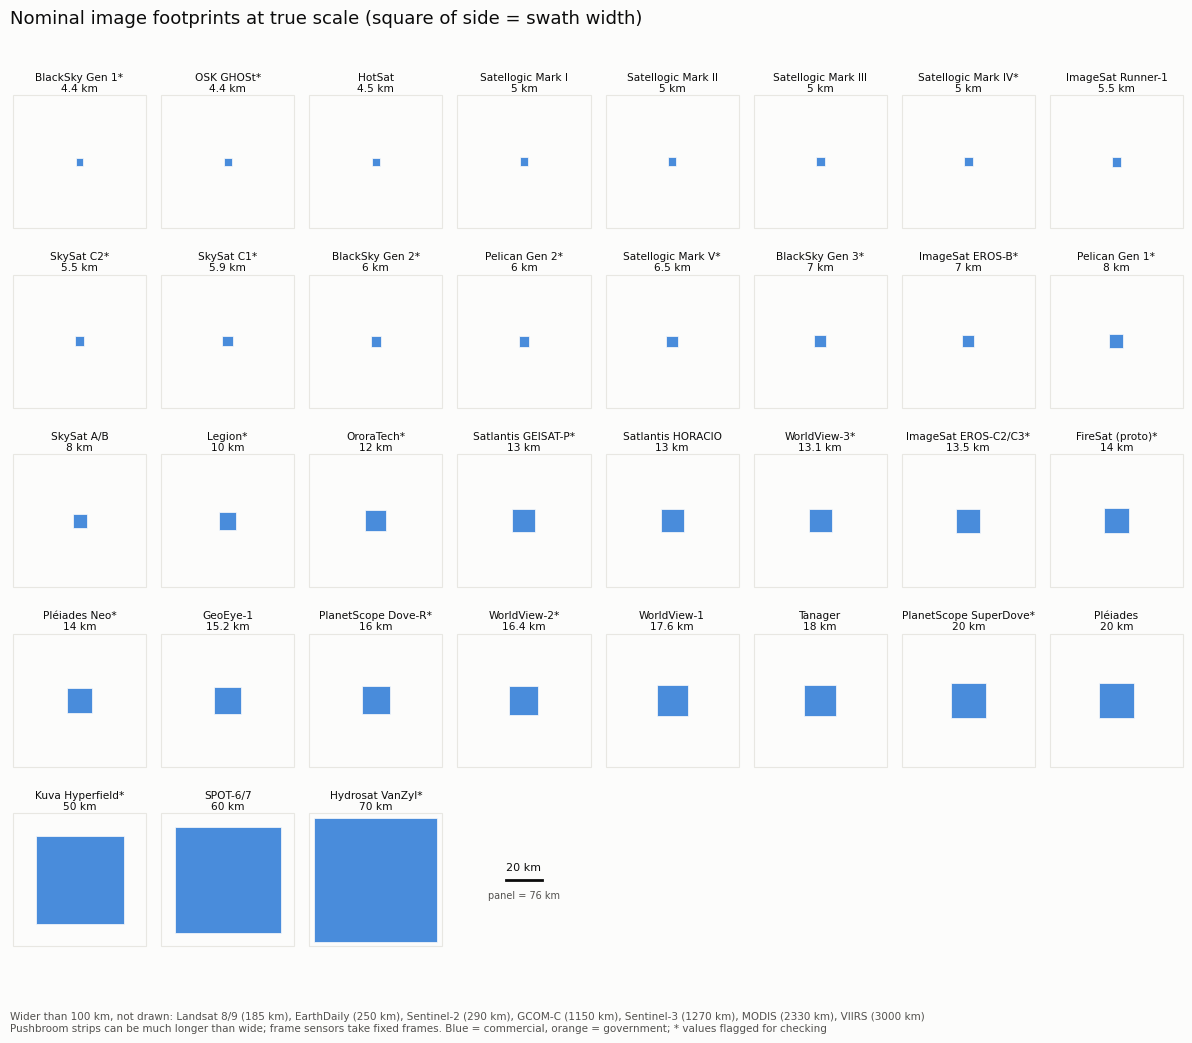

In [11]:
fig = vs.plot_footprints(groups, max_swath_km=100, flagged=FLAGGED)
fig.savefig(OUT_DIR / 'specs_footprints.png', dpi=DPI, bbox_inches='tight', facecolor=fig.get_facecolor())

## 7. Interactive dashboard

One HTML file with the same views, filterable by sector and status, with hover details (specs, open checks, proposed
edits) for every constellation, plus completeness, checks, proposed edits and a sortable table. Written to
`html/vendor_specs.html` (served by GitHub Pages once committed; link it from the timeline when ready).

In [12]:
path = vs.write_dashboard(raw, all_groups, issues, edits, DASHBOARD, edits_date=EDITS_DATE,
                          sheet_url=f'https://docs.google.com/spreadsheets/d/{SHEET_ID}/edit?gid={GID}')
print('wrote', path)

wrote /panfs/ccds02/home/pmontesa/code/csda_summaries/html/vendor_specs.html


## 8. Update loop with vendor documents (NASA Chat)

For one constellation at a time:

1. Run the next cell with `CONSTELLATION` set; copy the printed prompt.
2. In NASA Chat, attach the vendor documents from SharePoint and paste the prompt. The answer is CSV
   (`sensor,field,value,unit,document,page,quote`), only values the documents state.
3. Save the answer as a CSV on ADAPT (or paste it into `EXTRACTED` as text) and run the comparison cell: rows with
   `same = False` are proposed changes, with the document and page to cite in *Reference*.
4. Edit the sheet, then re-run this notebook.

In [13]:
CONSTELLATION = 'Legion'          # 'Constellation/Platform' as in the sheet
print(vs.extraction_prompt(raw, CONSTELLATION))

From the attached document(s), extract the specifications of the Legion satellites (LG-1, LG-2, LG-3, LG-4, LG-5, LG-6) for the fields below. Use only what the documents state; do not use outside knowledge and do not guess. If a value differs between satellites or generations, give one line per sensor.

Answer ONLY as CSV with this header:
sensor,field,value,unit,document,page,quote
- field: exactly as written below
- value: number or vocabulary term only (e.g. 0.34, Pushbroom, 2024-05-02)
- quote: the short text the value comes from
- leave out fields the documents do not give

Fields (unit or allowed values in [ ]; the current database value is shown for reference):
- Sensor Name  -- current: LG-1; LG-2; LG-3; LG-4; LG-5; LG-6
- Constellation/Platform  -- current: Legion
- Launch Date  [YYYY-MM-DD]  -- current: 2024-05-02; 2024-08-15; 2025-02-04
- Start Date  [YYYY-MM-DD, first usable data]  -- current: (empty)
- End Date  [YYYY-MM-DD]  -- current: (empty)
- Branded Name  -- current:

In [14]:
EXTRACTED = None                  # path to the CSV saved from NASA Chat, or the CSV text itself
if EXTRACTED:
    diff = vs.compare_extracted(raw, EXTRACTED, CONSTELLATION)
    print(f"{(~diff.same).sum()} of {len(diff)} extracted values differ from the sheet")
    display(diff)